# Flux uncertainties for blended point sources

This experiment compares Gaussian-mixture and diffusion networks on simulated images with two sources at known positions. The uncertain quantities are the two source fluxes. A numerical image-likelihood grid supplies the reference. The short run below checks execution rather than the accuracy reported in the paper.

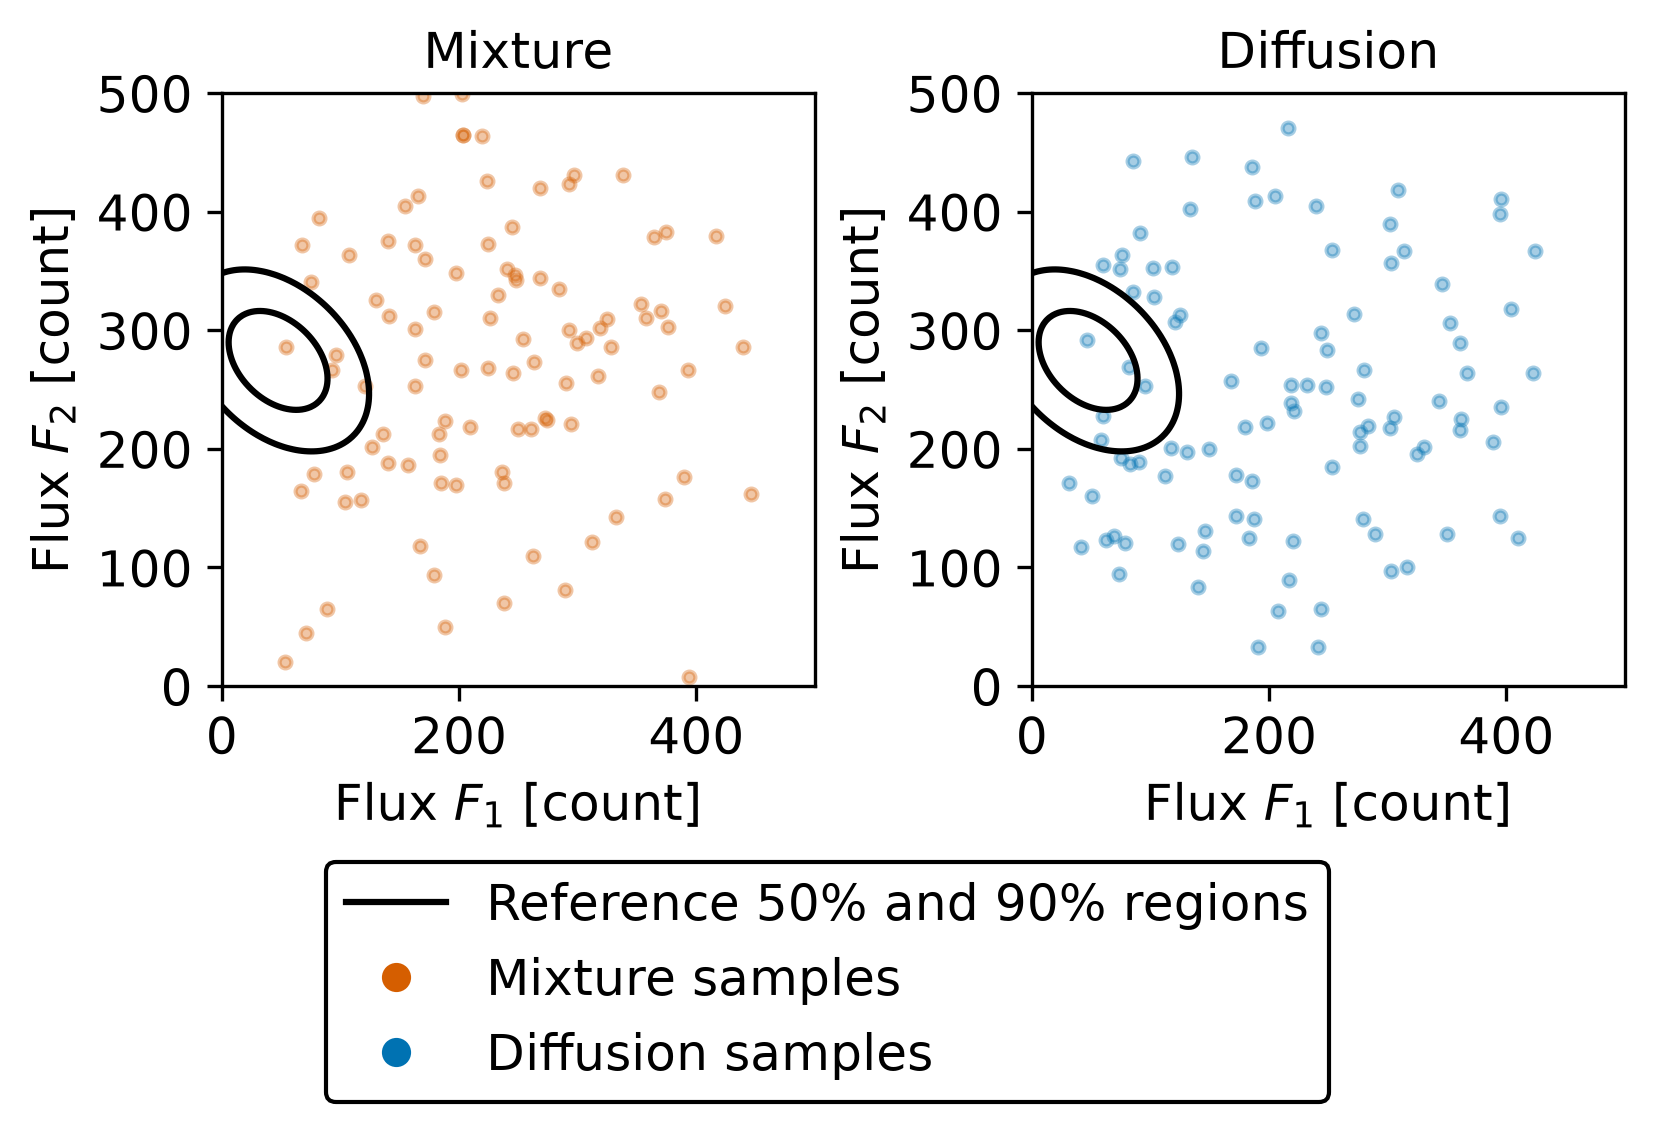

{'exact-grid': {'median_total_variation': 0.22366870327189597,
  'median_total_variation_95pct_scene_bootstrap_interval': [0.17879821519344094,
   0.268539191350351],
  'marginal_90pct_coverage_successes': [2, 2],
  'marginal_90pct_coverage': [1.0, 1.0],
  'marginal_90pct_coverage_95pct_wilson_interval': [[0.34237195288961925, 1.0],
   [0.34237195288961925, 1.0]],
  'median_sampling_seconds': None},
 'mixture': {'median_total_variation': 0.9532625612209501,
  'median_total_variation_95pct_scene_bootstrap_interval': [0.9402706836610912,
   0.966254438780809],
  'marginal_90pct_coverage_successes': [0, 2],
  'marginal_90pct_coverage': [0.0, 1.0],
  'marginal_90pct_coverage_95pct_wilson_interval': [[0.0, 0.6576280471103807],
   [0.34237195288961925, 1.0]],
  'median_sampling_seconds': 0.013693749999220017},
 'diffusion': {'median_total_variation': 0.9459101035201867,
  'median_total_variation_95pct_scene_bootstrap_interval': [0.9050685796776251,
   0.9867516273627484],
  'marginal_90pct_c

In [1]:
import json
from contextlib import redirect_stdout
from io import StringIO
from uuid import uuid4

from pcat.demo import display_example_visuals, load_example_namespace, run_example_script
from tdpy.verbosity import print

run_id = f"point_flux_notebook_{uuid4().hex[:12]}"
with redirect_stdout(StringIO()):
    run_example_script(
        "neural_proposal_efficiency/neural_posterior_diffusion.py",
        "--run-id", run_id,
        "--training-samples", "128", "--validation-scenes", "2",
        "--posterior-draws", "100", "--diffusion-steps", "8", "--epochs", "2",
    )
    example = load_example_namespace("neural_proposal_efficiency/neural_posterior_diffusion.py")
result_path = example["RESULTS_PATH"] / f"{run_id}_posterior.json"
print(f"Reading from {result_path.name}...")
with result_path.open(encoding="utf-8") as stream:
    summary = json.load(stream)["summary"]
with redirect_stdout(StringIO()):
    display_example_visuals("neural_proposal_efficiency", f"visuals/{run_id}_posterior.png")
summary